## Setup and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROC = Path("data/processed")          # change if your path differs
OUT = PROC / "profile"
OUT.mkdir(parents=True, exist_ok=True)

movies  = pd.read_csv(PROC / "C:\\Users\\JosephBotchway\\Documents\\StreamVault\\data\\processed\\movies_clean.csv")
ledger  = pd.read_csv(PROC / "C:\\Users\\JosephBotchway\\Documents\\StreamVault\\data\\processed\\id_ledger.csv")
talent  = pd.read_csv(PROC / "C:\\Users\\JosephBotchway\\Documents\\StreamVault\\data\\processed\\talent_long.csv")
quality = pd.read_csv(PROC / "C:\\Users\\JosephBotchway\\Documents\\StreamVault\\data\\processed\\quality_report.csv")

files = {"movies_clean": movies, "id_ledger": ledger,
         "talent_long": talent, "quality_report": quality}

In [4]:
for name, df in files.items():
    print(f"\n=== {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ===")
    print(df.dtypes.to_string())


=== movies_clean: 112 rows x 38 cols ===
id                             int64
title                            str
imdb_id                          str
release_date                     str
status                           str
adult                           bool
budget                         int64
revenue                        int64
runtime                        int64
vote_average                 float64
vote_count                     int64
popularity                   float64
original_language                str
collection_id                float64
collection_name                  str
release_year                   int64
flag_zero_budget                bool
flag_zero_revenue               bool
flag_implausible_budget         bool
flag_revenue_below_budget       bool
flag_not_released               bool
flag_missing_date               bool
flag_zero_runtime               bool
flag_low_votes                  bool
flag_missing_cpi                bool
flag_dup_imdb                   b

## 3. Overview chart
Rows per file, and the columns with the most missing values across all four files.

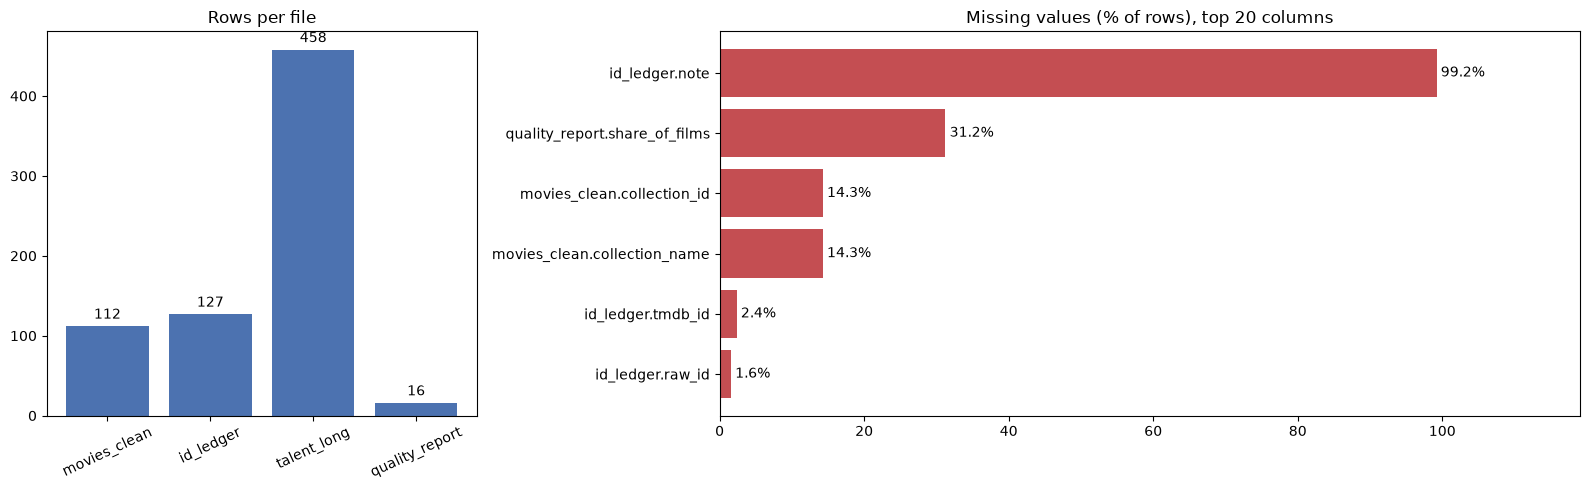

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 2]})

ax = axes[0]
sizes = pd.Series({n: len(d) for n, d in files.items()})
bars = ax.bar(sizes.index, sizes.values, color="#4C72B0")
ax.set_title("Rows per file")
ax.bar_label(bars, labels=[f"{v:,}" for v in sizes.values], padding=3)
ax.tick_params(axis="x", rotation=25)

ax = axes[1]
miss = pd.concat({n: d.isna().mean() * 100 for n, d in files.items()}).rename("pct")
miss = miss[miss > 0].sort_values().tail(20)
if len(miss):
    labels = [f"{f}.{c}" for f, c in miss.index]
    bars = ax.barh(labels, miss.values, color="#C44E52")
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in miss.values], padding=3)
    ax.set_xlim(0, max(miss.values) * 1.2)
    ax.set_title("Missing values (% of rows), top 20 columns")
else:
    ax.text(0.5, 0.5, "No missing values in any file", ha="center", va="center")
    ax.axis("off")

plt.tight_layout()
plt.savefig(OUT / "profile_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. movies_clean: numeric distributions
Histogram of each numeric column. Heavily skewed columns use a log10 scale. The dashed line is the median.

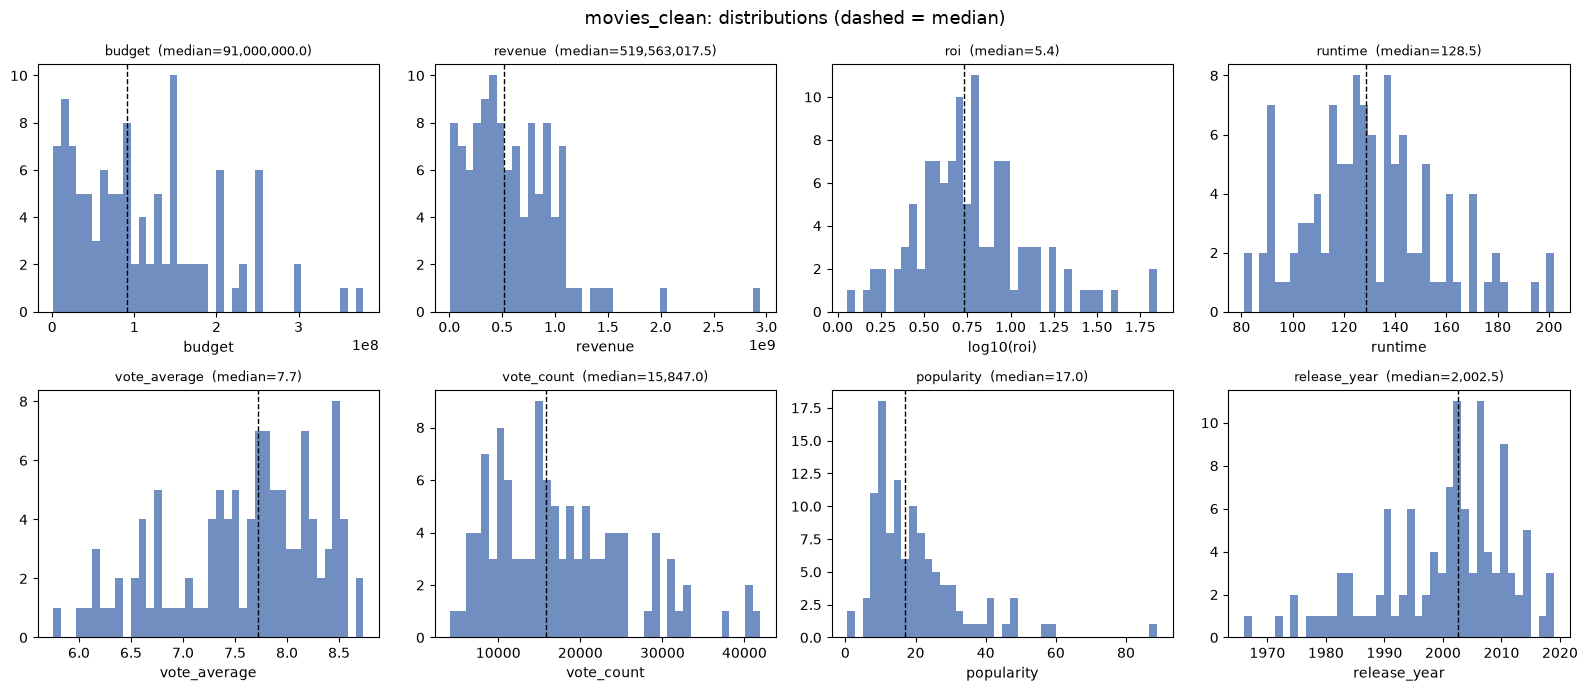

In [6]:
num_cols = [c for c in ["budget", "revenue", "roi", "runtime", "vote_average",
                        "vote_count", "popularity", "release_year"] if c in movies.columns]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    data = movies[col].dropna().astype(float)
    use_log = abs(data.skew()) > 2 and (data > 0).all()
    if use_log:
        ax.hist(np.log10(data), bins=40, color="#4C72B0", alpha=0.8)
        ax.set_xlabel(f"log10({col})")
    else:
        ax.hist(data, bins=40, color="#4C72B0", alpha=0.8)
        ax.set_xlabel(col)
    ax.axvline(np.log10(data.median()) if use_log else data.median(),
               color="black", ls="--", lw=1)
    ax.set_title(f"{col}  (median={data.median():,.1f})", fontsize=9)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")

fig.suptitle("movies_clean: distributions (dashed = median)", fontsize=13)
plt.tight_layout()
plt.savefig(OUT / "profile_movies_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. movies_clean: categories
Films per release year (split by franchise status), franchise vs standalone share, and the top 10 original languages.

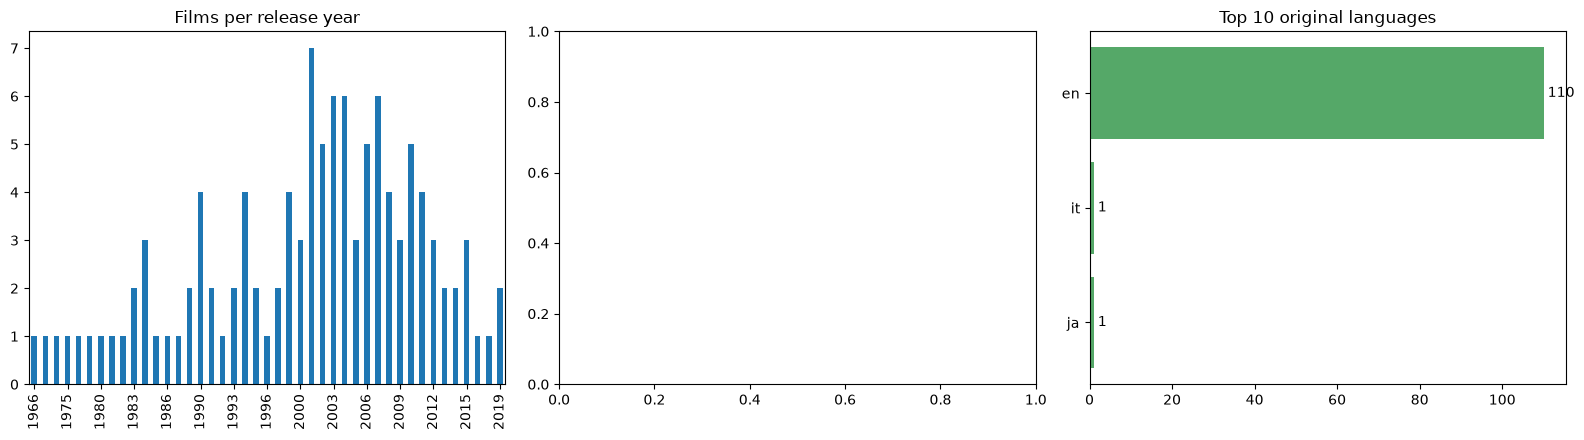

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

if "release_year" in movies.columns:
    if "is_franchise_member" in movies.columns:
        yr = (movies.groupby(["release_year", "is_franchise_member"]).size()
                    .unstack(fill_value=0))
        yr.plot(kind="bar", stacked=True, ax=axes[0], width=0.9,
                color=["#DD8452", "#4C72B0"])
        axes[0].legend(["Standalone", "Franchise"][:yr.shape[1]], fontsize=8)
    else:
        movies["release_year"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
    axes[0].set_title("Films per release year")
    axes[0].set_xlabel("")
    axes[0].set_xticks(axes[0].get_xticks()[::3])

if "is_franchise_member" in movies.columns:
    fc = movies["is_franchise_member"].value_counts()
    axes[1].pie(fc.values, labels=["Franchise" if k else "Standalone" for k in fc.index],
                autopct="%1.1f%%", colors=["#4C72B0", "#DD8452"], startangle=90)
    axes[1].set_title("Franchise vs standalone")

if "original_language" in movies.columns:
    lang = movies["original_language"].value_counts().head(10).sort_values()
    bars = axes[2].barh(lang.index, lang.values, color="#55A868")
    axes[2].bar_label(bars, padding=3)
    axes[2].set_title("Top 10 original languages")

plt.tight_layout()
plt.savefig(OUT / "profile_movies_categories.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. movies_clean: correlation
Spearman correlation between the numeric columns. Spearman is used because budget and revenue are heavily skewed.

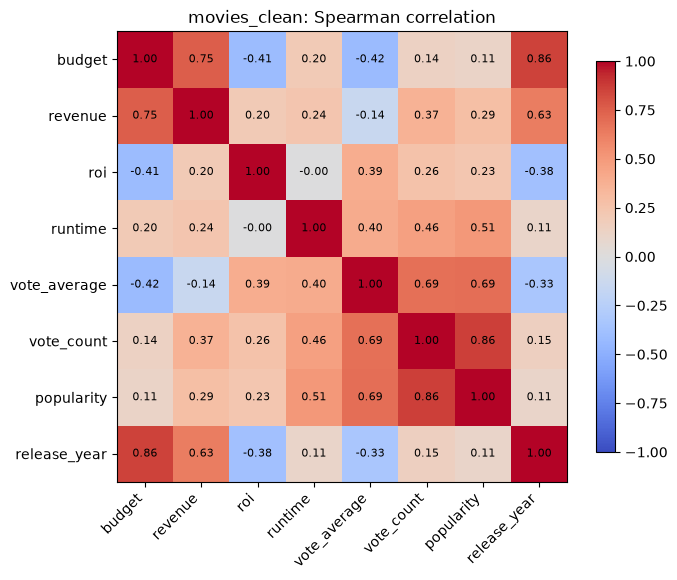

In [8]:
if len(num_cols) > 2:
    corr = movies[num_cols].astype(float).corr(method="spearman")
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
    ax.set_yticks(range(len(num_cols)), num_cols)
    for i in range(len(num_cols)):
        for j in range(len(num_cols)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title("movies_clean: Spearman correlation")
    plt.tight_layout()
    plt.savefig(OUT / "profile_movies_corr.png", dpi=150, bbox_inches="tight")
    plt.show()

## 8. talent_long
Rows by role, the most frequent people, and how many talent rows each film has.

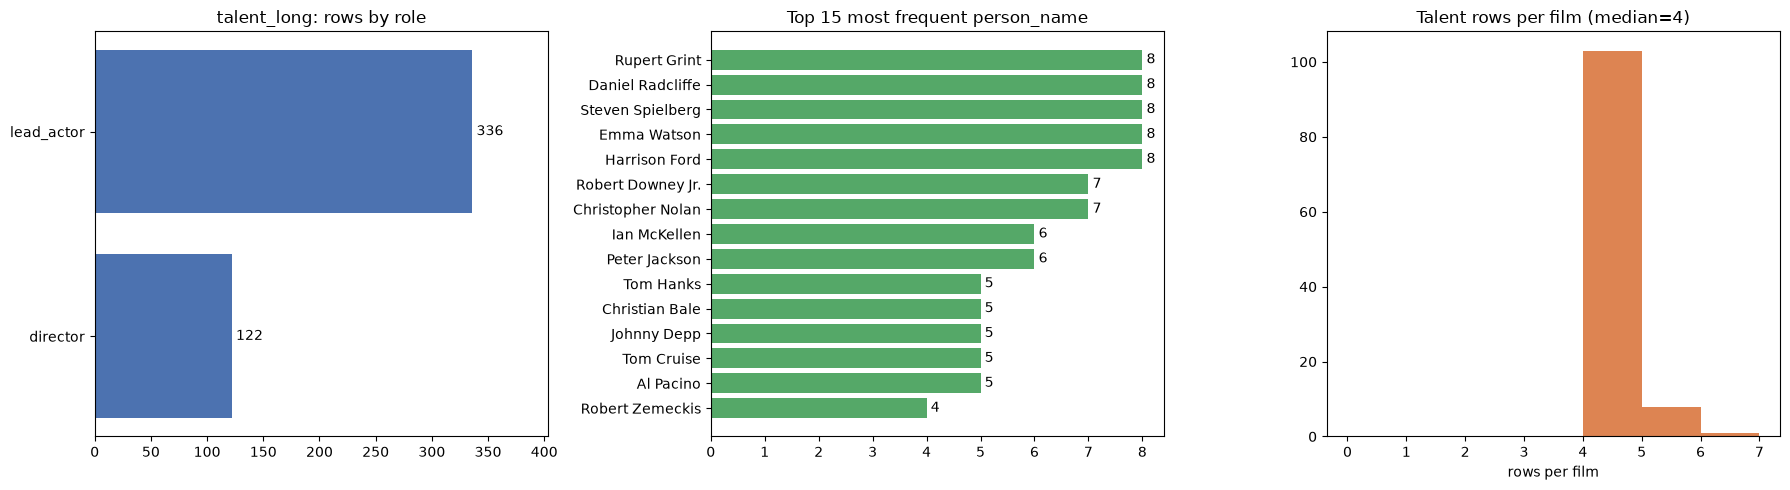

In [13]:
role_col = next((c for c in ["job", "role", "department", "type"] if c in talent.columns), None)
name_col = next((c for c in ["name", "person_name", "person_id"] if c in talent.columns), None)
film_col = "id" if "id" in talent.columns else None

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

if role_col:
    rc = talent[role_col].fillna("(missing)").value_counts().head(10).sort_values()
    bars = axes[0].barh(rc.index.astype(str), rc.values, color="#4C72B0")
    axes[0].bar_label(bars, labels=[f"{v:,}" for v in rc.values], padding=3)
    axes[0].set_xlim(0, rc.max() * 1.2)
    axes[0].set_title(f"talent_long: rows by {role_col}")

if name_col:
    top = talent[name_col].value_counts().head(15).sort_values()
    bars = axes[1].barh(top.index.astype(str), top.values, color="#55A868")
    axes[1].bar_label(bars, padding=3)
    axes[1].set_title(f"Top 15 most frequent {name_col}")

if film_col:
    per_film = talent.groupby(film_col).size()
    axes[2].hist(per_film, bins=range(0, int(per_film.max()) + 2, max(1, int(per_film.max() // 30) or 1)),
                 color="#DD8452")
    axes[2].set_title(f"Talent rows per film (median={per_film.median():.0f})")
    axes[2].set_xlabel("rows per film")

plt.tight_layout()
plt.savefig(OUT / "profile_talent.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. quality_report
Bar chart of the first numeric column against the first text column. If the layout is different, the table is shown instead.

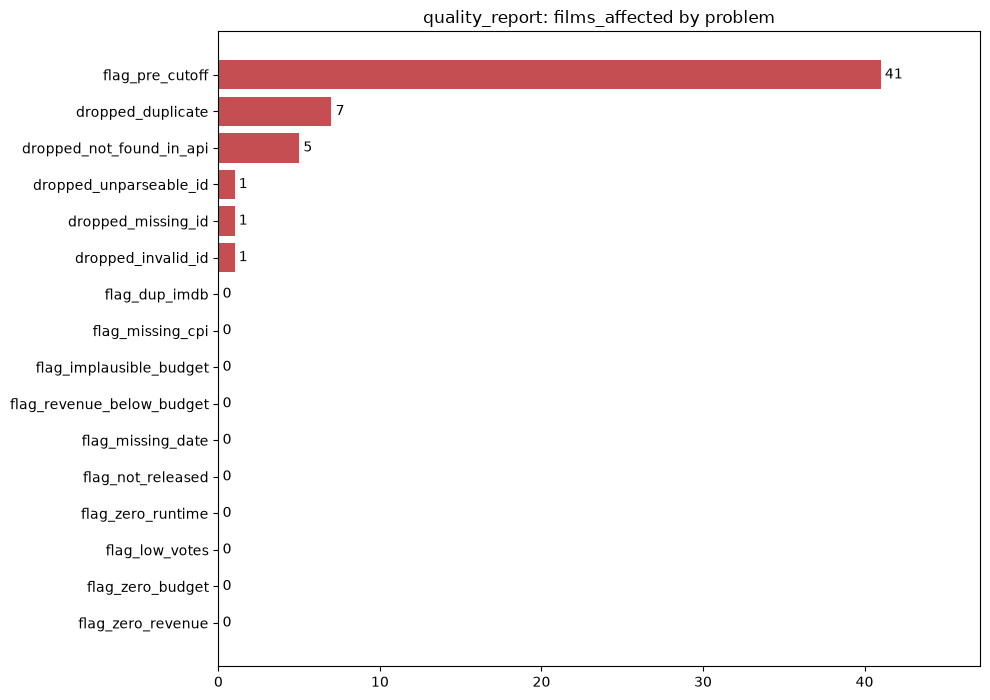

In [14]:
q_num = quality.select_dtypes("number").columns.tolist()
q_txt = [c for c in quality.columns if c not in q_num]

if q_num and q_txt:
    label_col, value_col = q_txt[0], q_num[0]
    q = quality[[label_col, value_col]].dropna().sort_values(value_col).tail(25)
    fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(q) + 1.5)))
    bars = ax.barh(q[label_col].astype(str), q[value_col], color="#C44E52")
    ax.bar_label(bars, labels=[f"{v:,.2f}".rstrip("0").rstrip(".") for v in q[value_col]], padding=3)
    ax.set_xlim(0, q[value_col].max() * 1.15 if q[value_col].max() > 0 else 1)
    ax.set_title(f"quality_report: {value_col} by {label_col}")
    plt.tight_layout()
    plt.savefig(OUT / "profile_quality.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    display(quality)